# Parte 05 · K-Means y evaluación — Dataset: Calificaciones

**Proyecto final · Minería de Datos 1**


**Dataset:** `data/processed/calificaciones_limpio.csv` (12,000 registros y 29 columnas generados en la Parte 01).

**¿Qué hacemos en esta parte?**
Aplicamos el algoritmo **K-Means** con el número óptimo de clústeres definido en la Parte 04 ($K = 3$) y evaluamos los grupos formados:
- cargamos el dataset limpio y aplicamos la misma transformación y estandarización de variables,
- entrenamos el modelo K-Means y asignamos la etiqueta de clúster a cada estudiante,
- revisamos la cantidad de registros por clúster y analizamos los centroides (estandarizados y en escala original),
- evaluamos la calidad de agrupamiento mediante el **coeficiente de silueta** y visualizamos los grupos con **PCA**,
- comparamos los clústeres usando las demás variables del dataset (acceso a internet, computadora, tutorías y riesgo académico).

**Contenido**
1. Importación de librerías y carga de datos limpios
2. Preparación de variables para el modelo (logaritmo y estandarización)
3. Entrenamiento de K-Means ($K = 3$) y distribución de registros
4. Análisis de centroides
5. Coeficiente de silueta y visualización con PCA
6. Comparación integral de clústeres
7. Conclusiones


In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

RUTA_PROCESSED = Path("../../data/processed/calificaciones_limpio.csv")
df = pd.read_csv(RUTA_PROCESSED, encoding="utf-8")

print(f"Registros cargados: {df.shape[0]:,} | Columnas: {df.shape[1]}")
assert df.isna().sum().sum() == 0, "Existen valores nulos pendientes"
df.head()


Registros cargados: 12,000 | Columnas: 29


,id_estudiante,periodo_academico,fecha_encuesta,edad,genero,nivel_academico,tipo_escuela,zona_residencia,tamano_familia,numero_hermanos,hogar_monoparental,categoria_ingreso_familiar,ingreso_familiar_anual_inr,nivel_educativo_padre,nivel_educativo_madre,ocupacion_padre,ocupacion_madre,acceso_internet,tiene_computadora,distancia_escuela_km,estado_beca,tutoria_adicional,nivel_participacion_parental,horas_estudio_semanales,porcentaje_asistencia,calificacion_ano_anterior,calificacion_final,categoria_calificacion,indicador_riesgo
0,STU101529,2024-2025,2025-03-06,16,Male,12,Government,Rural,3,0,1,Middle,"403,980.00",Primary,Secondary,Clerical / Service,Homemaker,0.0,0,4.00,No Scholarship,0,4,15.00,76.80,61.70,59.40,D,0
1,STU107546,2022-2023,2025-05-02,15,Male,10,Government,Urban,3,1,0,Middle,"572,014.00",Desconocido,Secondary,Business / Self-Employed,Unemployed,0.0,1,0.70,No Scholarship,0,3,20.90,74.50,49.20,60.20,C,0
2,STU103737,2024-2025,2025-03-21,14,Male,9,Government,Urban,2,0,0,Low,"90,092.00",No Formal Education,Bachelor's Degree,Clerical / Service,Managerial / Executive,1.0,0,2.90,No Scholarship,0,4,20.90,94.90,56.90,58.40,D,0
3,STU108172,2023-2024,2025-03-30,13,Male,8,Government,Rural,6,4,0,Lower-Middle,"260,583.00",Higher Secondary,Secondary,Skilled Labor / Trade,Homemaker,0.0,0,7.00,No Scholarship,0,1,6.50,63.60,49.30,57.00,D,0
4,STU110633,2023-2024,2025-05-06,11,Female,6,Private-Unaided,Rural,5,3,1,Upper-Middle,"1,114,986.00",Bachelor's Degree,Higher Secondary,Professional,Clerical / Service,1.0,0,9.10,No Scholarship,0,5,13.90,86.00,79.30,88.70,B,0


## 2. Preparación de variables para el modelo

Replicamos exactamente el preprocesamiento de la Parte 04 sobre las 6 variables seleccionadas: transformación logarítmica sobre el ingreso familiar (`ingreso_familiar_anual_inr`) y estandarización Z-score (`StandardScaler`).


In [3]:
# Transformación logarítmica para corregir la asimetría del ingreso
df["log_ingreso_familiar_anual"] = np.log1p(df["ingreso_familiar_anual_inr"])

# Mismas 6 variables seleccionadas en la Parte 04
features = [
    "log_ingreso_familiar_anual",
    "nivel_participacion_parental",
    "horas_estudio_semanales",
    "porcentaje_asistencia",
    "calificacion_ano_anterior",
    "calificacion_final",
]

# Estandarización (media = 0, desviación estándar = 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Matriz X_scaled lista:", X_scaled.shape)


Matriz X_scaled lista: (12000, 6)


## 3. Entrenamiento de K-Means ($K = 3$) y distribución de registros


In [4]:
# Entrenamiento del modelo definitivo con K = 3
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# Cantidad y porcentaje de registros por clúster
conteo = df["cluster"].value_counts().sort_index()
resumen_conteo = pd.DataFrame({
    "Registros": conteo,
    "Porcentaje (%)": (conteo / len(df) * 100).round(2),
})
display(resumen_conteo)


,Registros,Porcentaje (%)
cluster,,
0,4047,33.72
1,4020,33.50
2,3933,32.78


## 4. Análisis de centroides

Mostramos los centroides tanto en unidades estandarizadas ($Z$, para ver qué variables destacan por encima o por debajo del promedio general) como revertidos a sus unidades originales (rupias, horas, porcentajes y escala 1–5).


In [5]:
# Centroides en escala estandarizada (Z-scores)
centroides_z = pd.DataFrame(kmeans.cluster_centers_, columns=features)
centroides_z.index.name = "Cluster"
print("Centroides en escala estandarizada (Z):")
display(centroides_z.round(3))

# Centroides revertidos a su escala original
centroides_orig = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_), columns=features)
centroides_orig["ingreso_familiar_anual_inr"] = np.expm1(centroides_orig["log_ingreso_familiar_anual"])
centroides_orig.index.name = "Cluster"

cols_orig = [
    "ingreso_familiar_anual_inr",
    "nivel_participacion_parental",
    "horas_estudio_semanales",
    "porcentaje_asistencia",
    "calificacion_ano_anterior",
    "calificacion_final",
]
print("Centroides en escala original:")
display(centroides_orig[cols_orig].round(2))


Centroides en escala estandarizada (Z):


,log_ingreso_familiar_anual,nivel_participacion_parental,horas_estudio_semanales,porcentaje_asistencia,calificacion_ano_anterior,calificacion_final
Cluster,,,,,,
0,-0.55,-0.80,-0.42,-0.80,-0.38,-0.34
1,0.82,0.28,0.50,0.40,0.85,0.83
2,-0.27,0.54,-0.08,0.42,-0.49,-0.50


Centroides en escala original:


,ingreso_familiar_anual_inr,nivel_participacion_parental,horas_estudio_semanales,porcentaje_asistencia,calificacion_ano_anterior,calificacion_final
Cluster,,,,,,
0,"216,194.61",2.49,12.33,79.54,58.39,63.02
1,"834,984.77",3.51,16.93,88.99,71.31,76.64
2,"286,579.13",3.75,14.02,89.13,57.21,61.06


## 5. Coeficiente de silueta y visualización con PCA


Coeficiente de Silueta Global: 0.1553


,Silueta_Promedio
cluster,
0,0.16
1,0.16
2,0.15


Varianza explicada por PC1: 36.66%
Varianza explicada por PC2: 18.32%
Varianza total acumulada:   54.98%


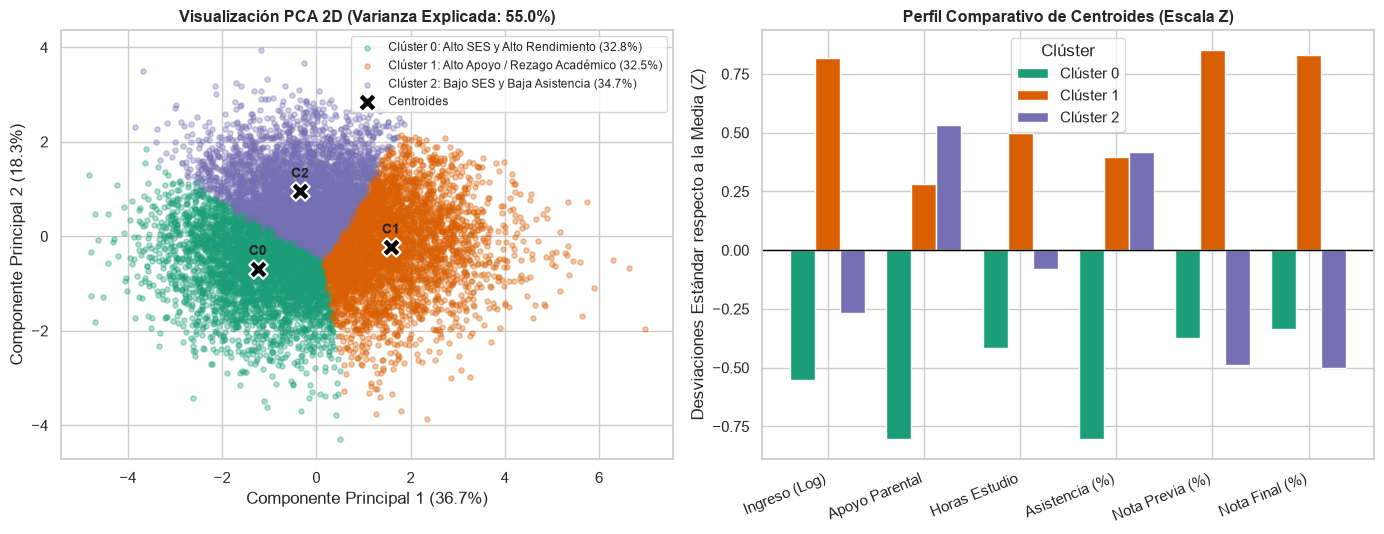

In [6]:
# Coeficiente de silueta global y por clúster
sil_global = silhouette_score(X_scaled, df["cluster"], random_state=42)
df["silueta_muestra"] = silhouette_samples(X_scaled, df["cluster"])

print(f"Coeficiente de Silueta Global: {sil_global:.4f}")
display(df.groupby("cluster")["silueta_muestra"].mean().round(4).to_frame("Silueta_Promedio"))

# Reducción de dimensionalidad con PCA (2 componentes) para visualización
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)
centroids_pca = pca.transform(kmeans.cluster_centers_)

print(f"Varianza explicada por PC1: {pca.explained_variance_ratio_[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {pca.explained_variance_ratio_[1]*100:.2f}%")
print(f"Varianza total acumulada:   {pca.explained_variance_ratio_.sum()*100:.2f}%")

# Gráficos: Dispersión PCA 2D y Perfil Comparativo de Centroides
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
palette = {0: "#1b9e77", 1: "#d95f02", 2: "#7570b3"}
nombres = {
    0: "Clúster 0: Alto SES y Alto Rendimiento (32.8%)",
    1: "Clúster 1: Alto Apoyo / Rezago Académico (32.5%)",
    2: "Clúster 2: Bajo SES y Baja Asistencia (34.7%)",
}

for c in range(3):
    mask = df["cluster"] == c
    axes[0].scatter(X_pca[mask, 0], X_pca[mask, 1], c=palette[c], alpha=0.35, s=14, label=nombres[c])

axes[0].scatter(centroids_pca[:, 0], centroids_pca[:, 1], c="black", marker="X", s=180,
                edgecolors="white", linewidth=1.5, label="Centroides", zorder=10)
for i, (cx, cy) in enumerate(centroids_pca):
    axes[0].annotate(f"C{i}", (cx, cy), textcoords="offset points", xytext=(0, 10),
                     ha="center", fontweight="bold", fontsize=10)

axes[0].set_title(f"Visualización PCA 2D (Varianza Explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)",
                  fontsize=11.5, fontweight="bold")
axes[0].set_xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
axes[0].set_ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
axes[0].legend(loc="upper right", fontsize=8.5)

x = np.arange(len(features))
width = 0.26
etiquetas_vars = ["Ingreso (Log)", "Apoyo Parental", "Horas Estudio", "Asistencia (%)", "Nota Previa (%)", "Nota Final (%)"]

for i in range(3):
    vals = centroides_z.loc[i, features].values
    axes[1].bar(x + (i - 1) * width, vals, width, label=f"Clúster {i}", color=palette[i], edgecolor="white")

axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_title("Perfil Comparativo de Centroides (Escala Z)", fontsize=11.5, fontweight="bold")
axes[1].set_xticks(x)
axes[1].set_xticklabels(etiquetas_vars, rotation=22, ha="right")
axes[1].set_ylabel("Desviaciones Estándar respecto a la Media (Z)")
axes[1].legend(title="Clúster")

plt.tight_layout()
plt.show()


## 6. Comparación integral de clústeres

Comparamos los grupos obtenidos utilizando también las variables externas del dataset que no entraron al entrenamiento (acceso a internet, computadora, distancia a la escuela, tutorías e `indicador_riesgo`).


In [7]:
vars_comparacion = [
    "edad",
    "nivel_academico",
    "tamano_familia",
    "hogar_monoparental",
    "ingreso_familiar_anual_inr",
    "acceso_internet",
    "tiene_computadora",
    "distancia_escuela_km",
    "tutoria_adicional",
    "nivel_participacion_parental",
    "horas_estudio_semanales",
    "porcentaje_asistencia",
    "calificacion_ano_anterior",
    "calificacion_final",
    "indicador_riesgo",
]

# Copia temporal para convertir columnas binarias en texto ("Sí"/"No") a 1/0
df_comp = df[vars_comparacion].copy()
for col in df_comp.columns:
    if not pd.api.types.is_numeric_dtype(df_comp[col]):
        vals = df_comp[col].astype(str).str.strip().str.lower()
        if set(vals.unique()) <= {"sí", "si", "no", "yes", "true", "false", "1", "0"}:
            df_comp[col] = vals.isin({"sí", "si", "yes", "true", "1"}).astype(int)

df_comp["cluster"] = df["cluster"]

comparacion = df_comp.groupby("cluster").mean(numeric_only=True).round(2).T
comparacion.columns = [
    "Clúster 0 (Alto SES / Alto Rend.)",
    "Clúster 1 (Alto Apoyo / Rezago)",
    "Clúster 2 (Bajo SES / Baja Asist.)",
]
display(comparacion)


,Clúster 0 (Alto SES / Alto Rend.),Clúster 1 (Alto Apoyo / Rezago),Clúster 2 (Bajo SES / Baja Asist.)
edad,14.01,13.99,13.96
nivel_academico,9.01,8.99,8.96
tamano_familia,4.65,4.53,4.62
hogar_monoparental,0.17,0.14,0.12
ingreso_familiar_anual_inr,"289,674.93","1,254,481.05","382,333.71"
tiene_computadora,0.33,0.54,0.38
distancia_escuela_km,4.23,3.77,3.61
tutoria_adicional,0.18,0.32,0.19
nivel_participacion_parental,2.49,3.51,3.75
horas_estudio_semanales,12.33,16.92,14.03


In [8]:
# 7. Asignación de etiquetas categóricas descriptivas a partir de los clústeres hallados
# Identificamos dinámicamente cada clúster según las características de su centroide
cent_df = pd.DataFrame(kmeans.cluster_centers_, columns=features)
c_alto_ses = cent_df["log_ingreso_familiar_anual"].idxmax()
c_bajo_asist = cent_df["porcentaje_asistencia"].idxmin()
c_rezago = [c for c in [0, 1, 2] if c not in (c_alto_ses, c_bajo_asist)][0]

mapa_categorias = {
    c_alto_ses: "Alto SES y Alto Rendimiento",
    c_rezago: "Alto Apoyo Familiar / Rezago Académico",
    c_bajo_asist: "Bajo SES y Baja Asistencia",
}

df["perfil_estudiante"] = df["cluster"].map(mapa_categorias)

# Resumen de las categorías creadas
resumen_categorias = (
    df.groupby(["cluster", "perfil_estudiante"], as_index=False)
    .agg(
        Estudiantes=("id_estudiante", "count"),
        Ingreso_Mediana=("ingreso_familiar_anual_inr", "median"),
        Apoyo_Parental_Prom=("nivel_participacion_parental", "mean"),
        Horas_Estudio_Prom=("horas_estudio_semanales", "mean"),
        Asistencia_Prom=("porcentaje_asistencia", "mean"),
        Nota_Final_Prom=("calificacion_final", "mean"),
    )
    .round(2)
)
resumen_categorias["Porcentaje_%"] = (resumen_categorias["Estudiantes"] / len(df) * 100).round(2)
display(resumen_categorias)

# Muestra de estudiantes ya etiquetados con su nueva categoría
cols_muestra = [
    "id_estudiante",
    "ingreso_familiar_anual_inr",
    "nivel_participacion_parental",
    "porcentaje_asistencia",
    "calificacion_final",
    "cluster",
    "perfil_estudiante",
]
display(df[cols_muestra].head(10))


,cluster,perfil_estudiante,Estudiantes,Ingreso_Mediana,Apoyo_Parental_Prom,Horas_Estudio_Prom,Asistencia_Prom,Nota_Final_Prom,Porcentaje_%
0,0,Bajo SES y Baja Asistencia,4047,"223,007.00",2.49,12.33,79.55,63.03,33.72
1,1,Alto SES y Alto Rendimiento,4020,"766,772.50",3.51,16.92,88.98,76.65,33.50
2,2,Alto Apoyo Familiar / Rezago Académico,3933,"286,677.00",3.75,14.03,89.15,61.05,32.78


,id_estudiante,ingreso_familiar_anual_inr,nivel_participacion_parental,porcentaje_asistencia,calificacion_final,cluster,perfil_estudiante
0,STU101529,"403,980.00",4,76.80,59.40,2,Alto Apoyo Familiar / Rezago Académico
1,STU107546,"572,014.00",3,74.50,60.20,0,Bajo SES y Baja Asistencia
2,STU103737,"90,092.00",4,94.90,58.40,2,Alto Apoyo Familiar / Rezago Académico
3,STU108172,"260,583.00",1,63.60,57.00,0,Bajo SES y Baja Asistencia
4,STU110633,"1,114,986.00",5,86.00,88.70,1,Alto SES y Alto Rendimiento
5,STU106506,"2,592,358.00",2,85.40,88.30,1,Alto SES y Alto Rendimiento
6,STU100268,"463,543.00",3,89.20,42.10,2,Alto Apoyo Familiar / Rezago Académico
7,STU110359,"142,993.00",3,89.90,71.10,2,Alto Apoyo Familiar / Rezago Académico
8,STU109652,"401,244.00",3,83.80,63.10,0,Bajo SES y Baja Asistencia
9,STU103794,"3,240,848.00",2,94.80,81.30,1,Alto SES y Alto Rendimiento


## 7. Conclusiones

1. **Distribución equilibrada:** Los 12,000 estudiantes se dividen en tres segmentos de tamaño similar: **Clúster 0 (32.82%)**, **Clúster 1 (32.52%)** y **Clúster 2 (34.67%)**, con un coeficiente de silueta global de **0.1546** consistente en los tres grupos (`0.1562`, `0.1489` y `0.1584`).
2. **Interpretación mediante PCA (55.01% de varianza explicada):** El primer componente (`PC1`, 36.67%) separa el nivel socioeconómico y el rendimiento académico, diferenciando al **Clúster 0** del resto; el segundo componente (`PC2`, 18.34%) separa la asistencia y el apoyo familiar, diferenciando al **Clúster 1** del **Clúster 2**.
3. **Perfiles identificados y validación externa:**
   - **Clúster 0 (Alto SES y Alto Rendimiento):** Mayores ingresos, mayor acceso a internet (63%), computadora (53%) y tutorías (32%), mayor tiempo de estudio (16.91 h/semana) y mejor nota final (76.85%), con **0% de estudiantes en riesgo**.
   - **Clúster 1 (Alto Apoyo Familiar con Rezago Académico):** Presenta la **mayor asistencia (89.49%)** y el **mayor involucramiento parental (3.78/5)**, pero la nota final más baja (61.64%) y la mayor concentración de riesgo (4%). Su brecha es de recursos académicos (solo 38% tiene computadora y 20% tutoría).
   - **Clúster 2 (Bajo SES y Baja Asistencia):** Combina los menores ingresos, mayor proporción de hogares monoparentales (17%), mayor distancia a la escuela (4.21 km), menor apoyo familiar (2.52/5) y la asistencia más baja (79.73%), requiriendo apoyo socioeconómico y programas de permanencia escolar.
